# Effective dimensions results plotting
*Collects analysis data and calculates quantum model's effective dimension*

**By:** Adrian Panasiewicz and Jacob Cybulski<br>
**Date:** May-November 2026<br>

In [1]:
import os
import copy
import pickle
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
from itertools import zip_longest

## Plotting function

In [2]:
# Exponential Moving Target used to smooth the lines 
def smooth(scalars, weight):  # Weight between 0 and 1
    last = scalars[0]  # First value in the plot (first timestep)
    smoothed = list()
    for point in scalars:
        smoothed_val = last * weight + (1 - weight) * point  # Calculate smoothed value
        smoothed.append(smoothed_val)                        # Save it
        last = smoothed_val                                  # Anchor the last smoothed value
        
    return smoothed


def plot_many_series(series, smooth_weight=0, xlabel='Iterations', ylabel='Score', figsize=(12, 6), dpi=300, 
                     title='Series Score vs Iteration', labels=None, xlim=None, ylim=None, pref='', colors=None, 
                     loss_curve=None, loss_color='red', loss_label='Loss', legend_loc='best', save_plot=None):

    if labels is None: labels = [None]*len(series)
    if colors is None:
        colors = ['tab:blue', 'tab:orange' ,'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
    if loss_curve is not None:
        loss_mean, loss_sem = loss_curve

    # plt.rcParams['figure.figsize'] = figsize
    # plt.rcParams['figure.dpi'] = dpi
    
    fig, ax1 = plt.subplots(figsize=figsize, dpi=dpi)

    curve_lines = []
    for c in range(len(series)):
        transposed = list(zip_longest(*series[c], fillvalue=np.nan))
        min_curve = smooth([np.nanmin(col) for col in transposed], smooth_weight)
        max_curve = smooth([np.nanmax(col) for col in transposed], smooth_weight)
        mean_curve = smooth([np.nanmean(col) for col in transposed], smooth_weight)        
        if labels[c] is None:
            line = plt.plot(range(1, len(mean_curve)+1), mean_curve, color = colors[c], label=f'Series ({c})')[0]
        else:
            line = plt.plot(range(1, len(mean_curve)+1), mean_curve, color = colors[c], label=labels[c])[0]
        curve_lines.append(line)
        ax1.fill_between(range(1, len(mean_curve)+1), max_curve, min_curve, color = colors[c], alpha = 0.2)
        
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel(ylabel)
    if xlim is not None: ax1.set_xlim(xlim)
    if ylim is not None: ax1.set_ylim(ylim)

    if loss_curve is not None:
        ax2 = ax1.twinx()
        ax2.set_ylabel(loss_label)
        
        ebars = ax2.errorbar(
            range(1, len(loss_mean)+1), 
            loss_mean, 
            yerr=loss_sem,      # Specify the vertical error bounds
            fmt='--',           # Format string: '-' connects lines, 'o' makes circular markers
            color=loss_color,   # Color of the line and markers
            ecolor=loss_color,  # Color of the error bars
            elinewidth=1,       # Width of the error bar lines
            capsize=3,          # Adds horizontal caps to the ends of the error bars
            capthick=1,       # Thickness of the horizontal caps
            label=loss_label
        )   
        curve_lines.append(ebars)
        
    all_labels = [l.get_label() for l in curve_lines]
    ax1.legend(curve_lines, all_labels, loc=legend_loc)
    fig.tight_layout()
    plt.title(title)
    if save_plot is not None:
        os.makedirs(os.path.dirname(save_plot), exist_ok=True)
        ext = os.path.splitext(save_plot)[1][1:]
        plt.savefig(save_plot, format=ext, bbox_inches='tight')
    plt.show()

def plot_means_n_errs(means, errs, mins=None, maxes=None, loss_curve=None, 
    smooth_weight=0, xlabel='Circuit depth', ylabel='Effective dimension', figsize=(12, 6), dpi=300, 
    title='Effective dimension for series', labels=None, xlim=None, ylim=None, pref='', colors=None, 
    loss_color='red', loss_label='Loss', legend_loc='best', save_plot=None):

    if labels is None: labels = [None]*len(means)
    if colors is None:
        colors = ['tab:blue', 'tab:orange' ,'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
    if loss_curve is not None:
        loss_mean, loss_sem = loss_curve
    
    fig, ax1 = plt.subplots(figsize=figsize, dpi=dpi)

    curve_lines = []
    for c in range(len(means)):
        mean_curve = smooth(means[c], smooth_weight)
        means_less_curve = smooth([m-e for m, e in zip(means[c], errs[c])], smooth_weight)
        means_plus_curve = smooth([m+e for m, e in zip(means[c], errs[c])], smooth_weight)
        if labels[c] is None:
            line = ax1.plot(range(1, len(mean_curve)+1), mean_curve, color = colors[c], label=f'Series ({c})')[0]
        else:
            line = ax1.plot(range(1, len(mean_curve)+1), mean_curve, color = colors[c], label=labels[c])[0]
        curve_lines.append(line)
        ax1.fill_between(range(1, len(mean_curve)+1), means_plus_curve, means_less_curve, color = colors[c], alpha = 0.2)
        if mins is not None:
            min_curve = smooth(mins[c], smooth_weight)
            ax1.plot(range(1, len(min_curve)+1), min_curve, ls=':', color = colors[c], alpha = 0.5)
        if maxes is not None:
            max_curve = smooth(maxes[c], smooth_weight)
            ax1.plot(range(1, len(max_curve)+1), max_curve, ls=':', color = colors[c], alpha = 0.5)

    ax1.grid(True, alpha=0.3)
    ax1.set_xticks(range(1, len(mean_curve)+1))
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel(ylabel)
    if xlim is not None: ax1.set_xlim(xlim)
    if ylim is not None: ax1.set_ylim(ylim)

    if loss_curve is not None:
        ax2 = ax1.twinx()
        ax2.set_ylabel(loss_label)
        
        ebars = ax2.errorbar(
            range(1, len(loss_mean)+1), 
            loss_mean, 
            yerr=loss_sem,      # Specify the vertical error bounds
            fmt='--',           # Format string: '-' connects lines, 'o' makes circular markers
            color=loss_color,   # Color of the line and markers
            ecolor=loss_color,  # Color of the error bars
            elinewidth=1,       # Width of the error bar lines
            capsize=3,          # Adds horizontal caps to the ends of the error bars
            capthick=1,       # Thickness of the horizontal caps
            label=loss_label
        )   
        curve_lines.append(ebars)
        
    all_labels = [l.get_label() for l in curve_lines]
    ax1.legend(curve_lines, all_labels, loc=legend_loc)
    fig.tight_layout()
    plt.title(title)
    if save_plot is not None:
        os.makedirs(os.path.dirname(save_plot), exist_ok=True)
        ext = os.path.splitext(save_plot)[1][1:]
        plt.savefig(save_plot, format=ext, bbox_inches='tight')
    plt.show()

## Helper functions

In [3]:
def parameter_count_factory(depth):
    return SimpleNamespace(parameter_count=12 * int(depth))


def mean_and_sem(values):
    values = np.stack(values, axis=0).astype(float)
    mean = values.mean(axis=0)
    sem = values.std(axis=0, ddof=1) / np.sqrt(values.shape[0])
    return mean, sem


def aggregate_results(runs, key):
    results = [run[key] for run in runs]
    depths = np.asarray(results[0].depths)

    if any(
        not np.array_equal(np.asarray(result.depths), depths)
        for result in results
    ):
        raise ValueError(f"Depths differ between runs for {key}.")

    mean, sem = mean_and_sem(
        [np.asarray(result.means, dtype=float) for result in results]
    )

    aggregated = copy.copy(results[0])
    object.__setattr__(aggregated, "means", mean)
    object.__setattr__(aggregated, "standard_errors", sem)

    return aggregated


def aggregate_uneven_results(runs, key):
    results = [run[key] for run in runs]
    means = [float(np.mean(r.means)) for r in results]
    sems = [float(np.std(r.means, ddof=1) / np.sqrt(len(r.depths))) for r in results]

    aggregated = copy.copy(results[0])
    object.__setattr__(aggregated, "means", means)
    object.__setattr__(aggregated, "standard_errors", sems)

    return aggregated


def aggregate_uneven_eds_list(runs, key):
    results = [run[key] for run in runs]
    runs_no = len(results)
    means_list = [r.means for r in results]
    depths = [len(l) for l in means_list]
    return means_list, depths

def aggregate_uneven_eds(runs, key):
    means_list, depths = aggregate_uneven_eds_list(runs, key)
    high_depth = max(depths)
    depth_vals = []
    for d in range(high_depth):
        vals = []
        for l in means_list:
            if len(l) > d:
                vals.append(l[d])
        depth_vals.append(vals)
    eds_mean = [float(np.mean(dvals)) for dvals in depth_vals]
    eds_min = [float(np.min(dvals)) for dvals in depth_vals]
    eds_max = [float(np.max(dvals)) for dvals in depth_vals]
    eds_sem = [float(np.std(dvals) / np.sqrt(len(dvals))) for dvals in depth_vals]
    return eds_mean, eds_min, eds_max, eds_sem

def aggregate_uneven_losses(runs, key):
    results = [run[key] for run in runs]
    losses = [[r[depth] for depth in sorted(r)] for r in results]
    depths = [len(l) for l in losses]
    high_depth = max(depths)
    depth_vals = []
    for d in range(high_depth):
        vals = []
        for l in losses:
            if len(l) > d:
                vals.append(l[d])
        depth_vals.append(vals)
    loss_mean = [float(np.mean(dvals)) for dvals in depth_vals]
    loss_sem = [float(np.std(dvals) / np.sqrt(len(dvals))) for dvals in depth_vals]

    return loss_mean, loss_sem, depths

## Data collection

In [4]:
results_dir = Path("results")
charts_dir = Path("charts")
seeds = range(2026, 2033)
runs = []

for seed in seeds:
    ext_path = results_dir / f"depth_11_15_extension_{seed}.pkl"
    path = results_dir / f"trained_prefix_led_ged_results_{seed}.pkl"
    if ext_path.is_file():
        print(f'Collecting *extended seed: {seed}')
    else:
        print(f'Collecting  standard seed: {seed}')
    with path.open("rb") as f:
        runs.append(pickle.load(f))

led_means, led_min, led_max, led_sem = aggregate_uneven_eds(runs, "led_result")
ged_means, ged_min, ged_max, ged_sem = aggregate_uneven_eds(runs, "ged_result")
loss_mean, loss_sem, loss_max_depths = aggregate_uneven_losses(runs, "test_losses")

### Sample data

In [5]:
(led_means, led_sem)

([0.42710054939097103,
  0.5027102351823326,
  0.5687867051317589,
  0.6142310331801841,
  0.5719291374636777,
  0.5993805004209348,
  0.6366369819401635,
  0.5623866662858645,
  0.5248885763022021,
  0.5404212186810056,
  0.5866173808698825,
  0.5098445119102277,
  0.47968630676781066,
  0.3265814890035377,
  0.5265862547135961],
 [0.004470166624875279,
  0.012479935116142867,
  0.037371136900777445,
  0.031996140104192224,
  0.03619618234043975,
  0.040893650257035855,
  0.03989418507813762,
  0.051656645400309495,
  0.04903471757707051,
  0.05113292534554346,
  0.04843139924972845,
  0.05864959879305307,
  0.06990435019878105,
  0.05632198648626776,
  0.05036375160749255])

In [6]:
(loss_mean, loss_sem, loss_max_depths)

([0.0028296746596338587,
  0.002462908792105939,
  0.0021266681777678885,
  0.0014872348319630222,
  0.0013853943774493336,
  0.0009210786890226757,
  0.0007037313893250685,
  0.000905851772782228,
  0.0006820959204101137,
  0.0006851647035244188,
  0.0005316933771509402,
  0.0005773603546004721,
  0.000732511317680467,
  0.0017090999960512304,
  0.0004112331828808887],
 [5.1364550216302876e-05,
  0.0001556083171240507,
  0.00015818443652072396,
  0.00017277257659656484,
  0.00017263367780235022,
  9.515332394275661e-05,
  0.00012038588599551931,
  0.00020647458939953246,
  0.00013130819305512455,
  0.00010708216530636414,
  0.00010691693276206263,
  0.000131474587844312,
  0.00031847354570977094,
  0.00024219311796839404,
  0.0001205145798983149],
 [15, 15, 10, 10, 15, 15, 15])

## Plot normalized and unnormalized effective dimension

### Normalized ED plot

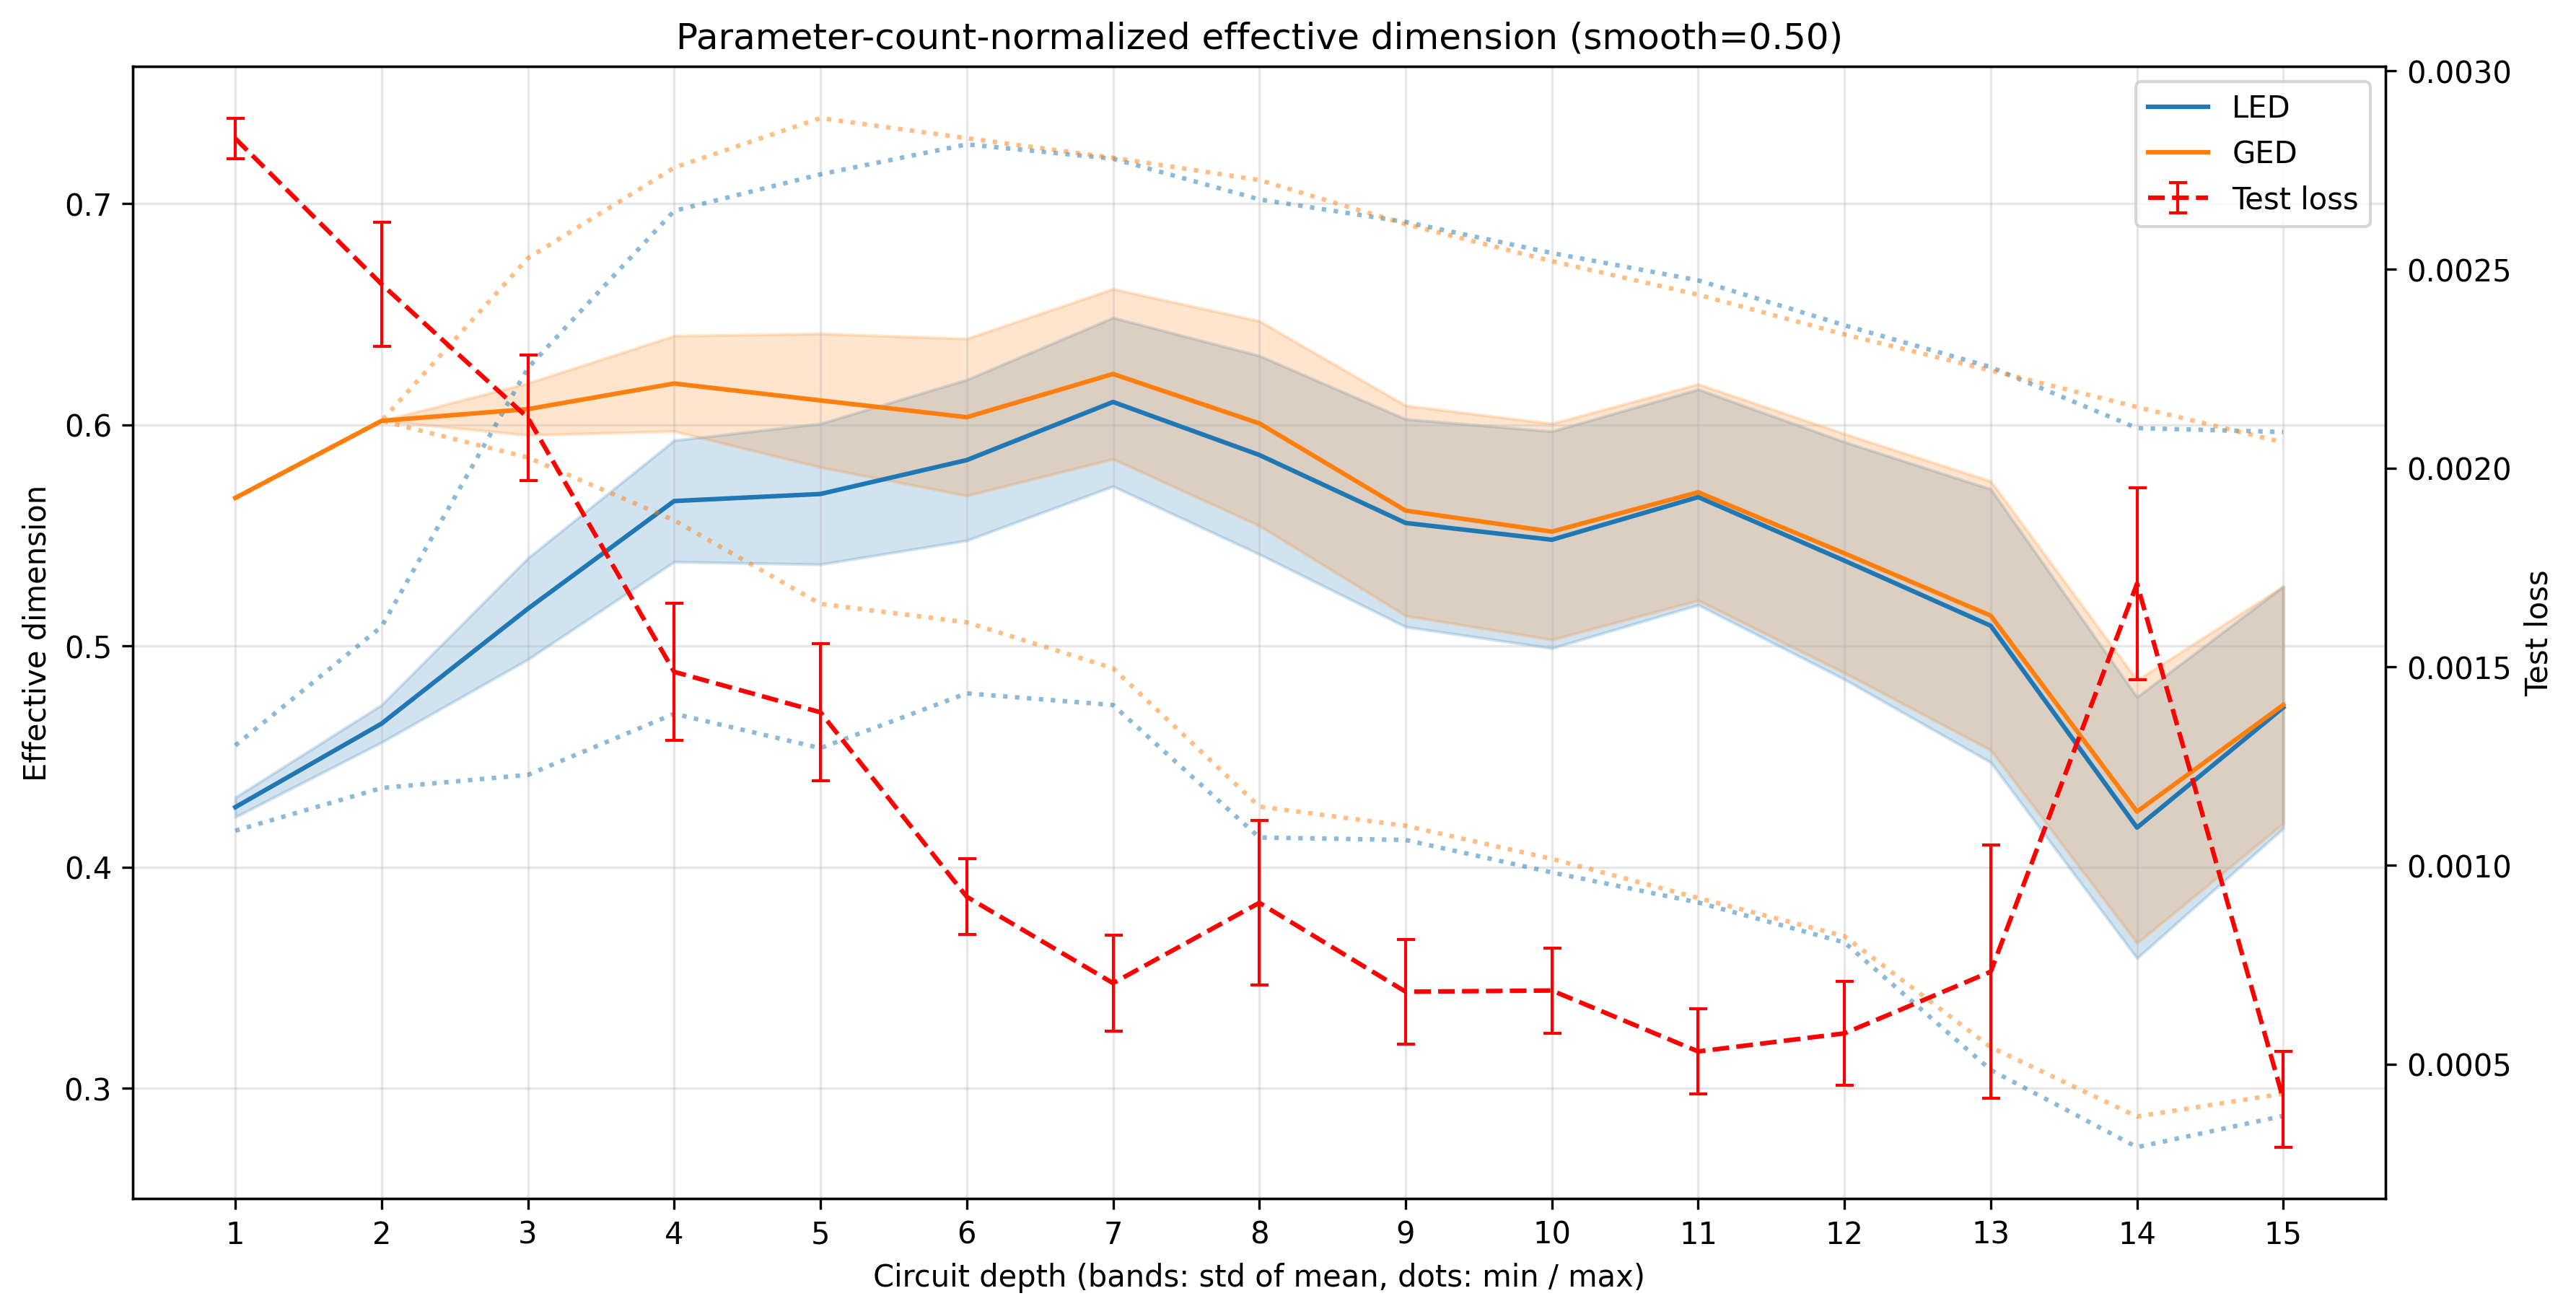


Plot saved in:  charts/eff_dim_norm_d10_d15.png


In [7]:
smoothing = 0.5
norm_plot_file_name = charts_dir / f'eff_dim_norm_d{min(loss_max_depths)}_d{max(loss_max_depths)}.png'
plot_means_n_errs([led_means, ged_means], [led_sem, ged_sem], 
    mins=[led_min, ged_min], maxes=[led_max, ged_max], loss_curve=(loss_mean, loss_sem), 
    smooth_weight=smoothing, xlabel='Circuit depth (bands: std of mean, dots: min / max)', ylabel='Effective dimension', 
    title='Parameter-count-normalized effective dimension'+('' if (smoothing<0.001) else f' (smooth={smoothing:0.2f})'), 
    labels=['LED', 'GED'], loss_label='Test loss', legend_loc='best', figsize=(12, 6), dpi=300,
    save_plot=norm_plot_file_name) 
print('\nPlot saved in: ', norm_plot_file_name)

### Unnormalized ED plot

In [8]:
### Unnormalize data
pcf = parameter_count_factory
led_unn_means = [led_means[d] * pcf(d).parameter_count for d in range(len(led_means))]
led_unn_min =   [led_min[d] * pcf(d).parameter_count for d in range(len(led_min))]
led_unn_max =   [led_max[d] * pcf(d).parameter_count for d in range(len(led_max))]
led_unn_sem =   [led_sem[d] * pcf(d).parameter_count for d in range(len(led_sem))]
ged_unn_means = [ged_means[d] * pcf(d).parameter_count for d in range(len(ged_means))]
ged_unn_min =   [ged_min[d] * pcf(d).parameter_count for d in range(len(ged_min))]
ged_unn_max =   [ged_max[d] * pcf(d).parameter_count for d in range(len(ged_max))]
ged_unn_sem =   [ged_sem[d] * pcf(d).parameter_count for d in range(len(ged_sem))]

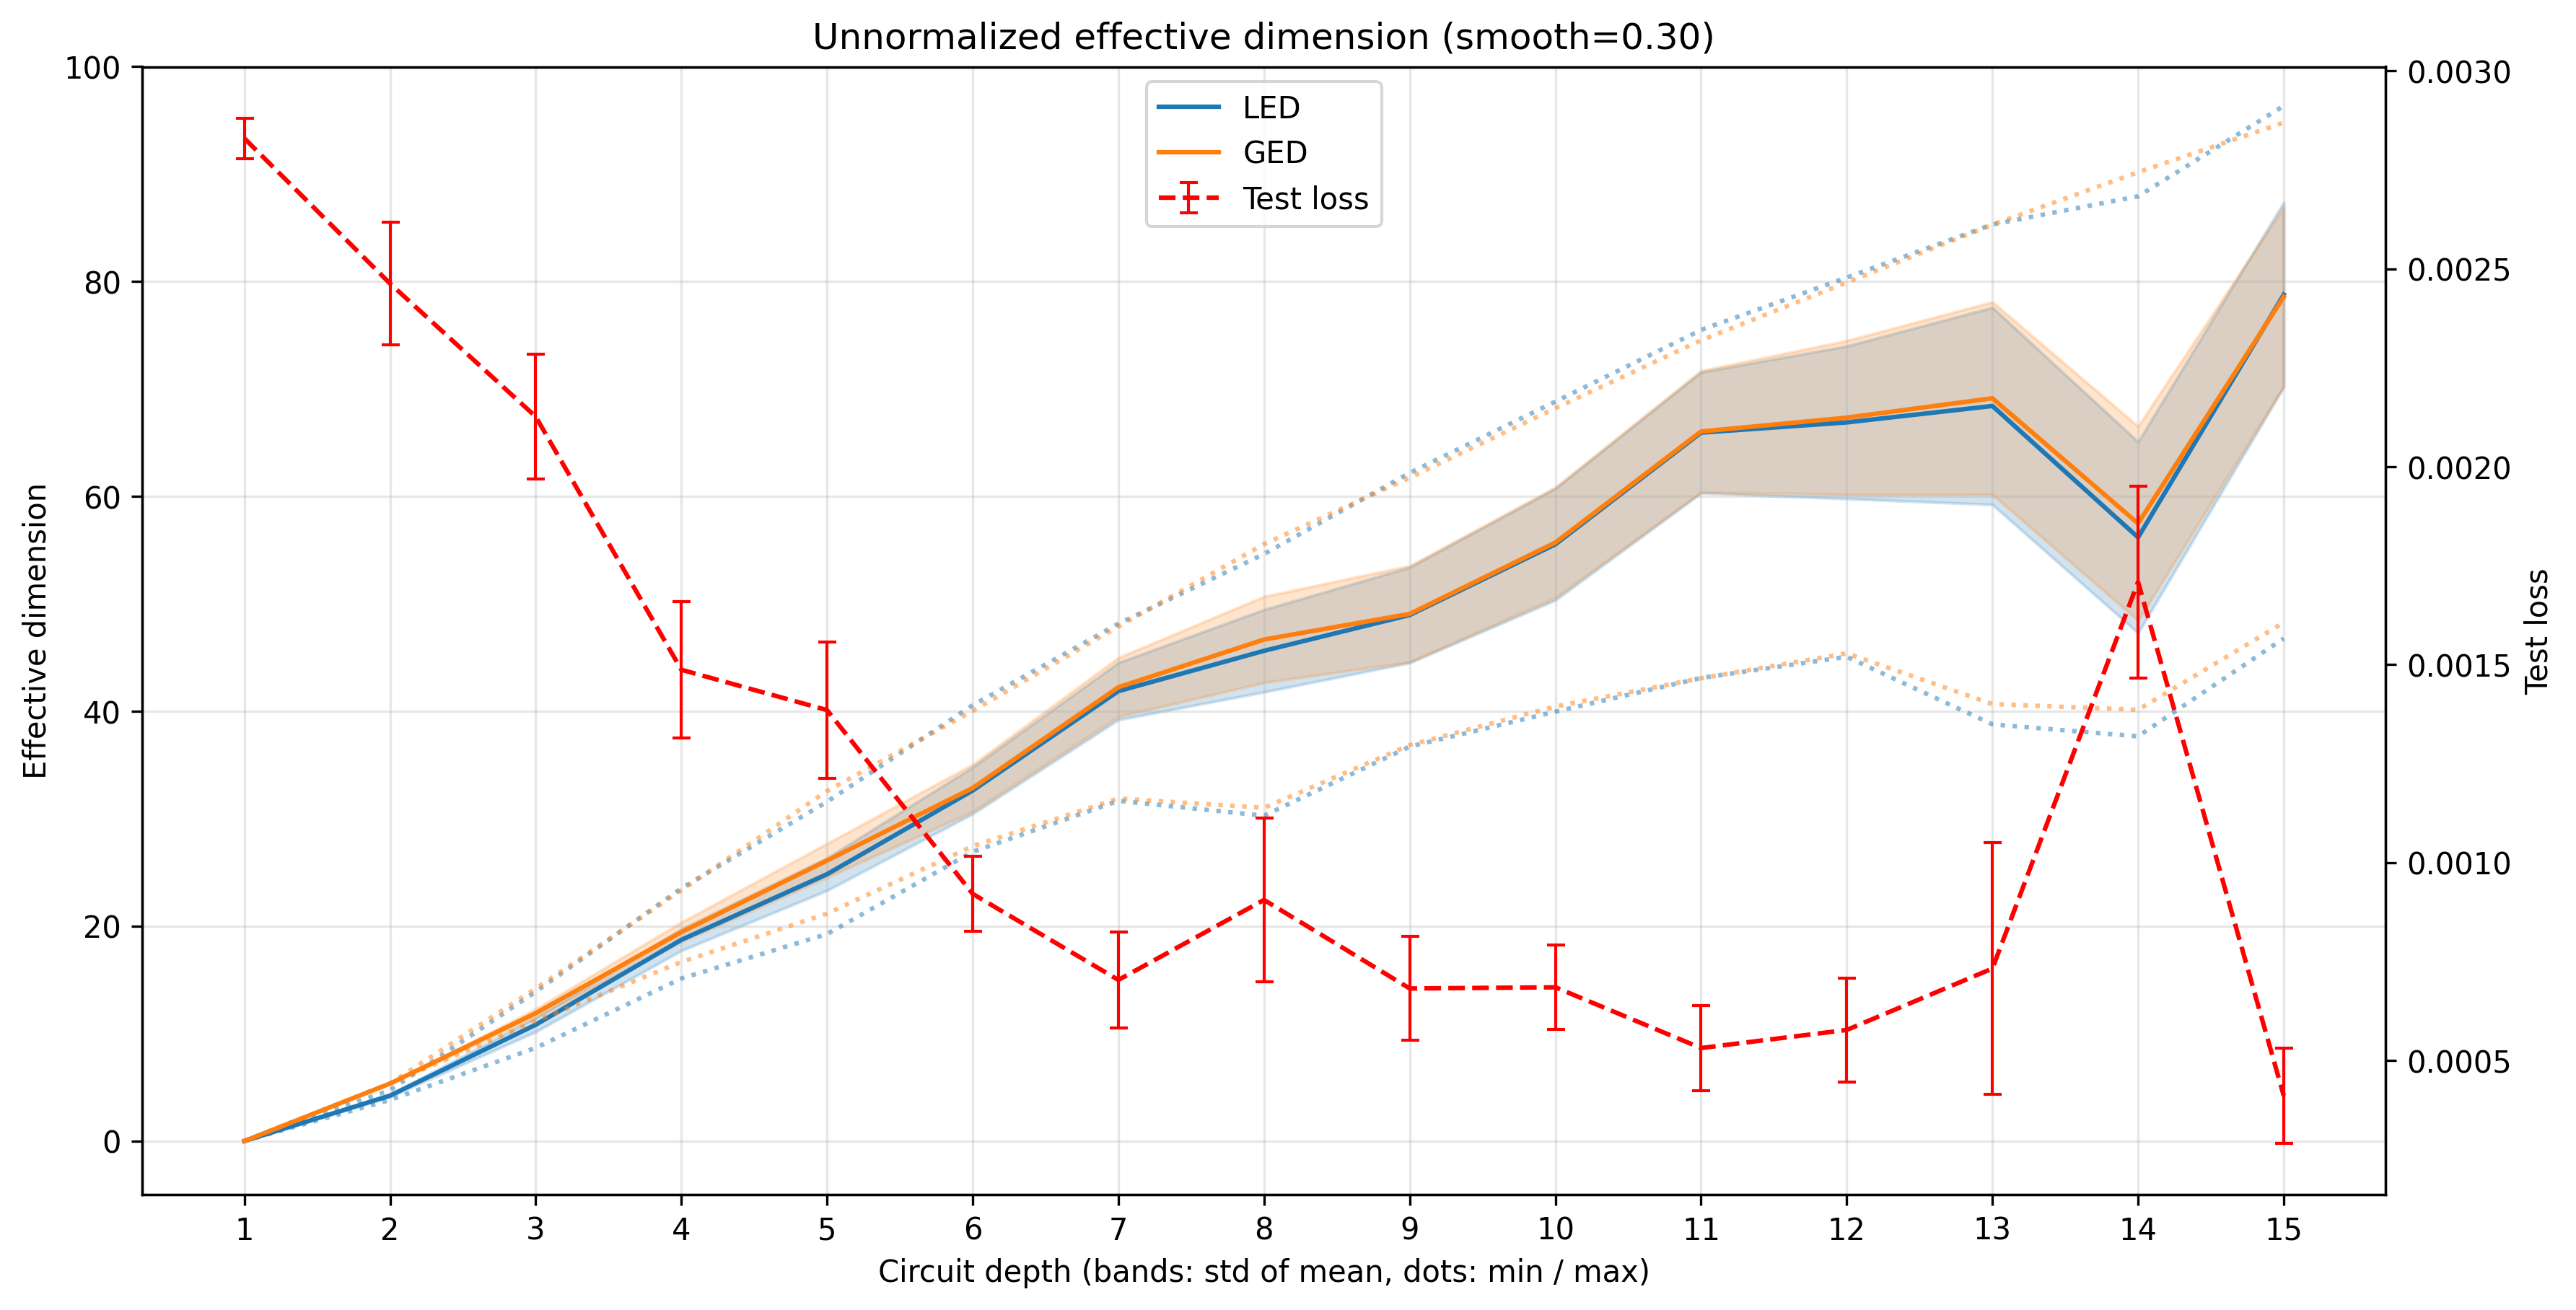


Plot saved in:  charts/eff_dim_unnorm_d10_d15.png


In [9]:
smoothing = 0.3
unnorm_plot_file_name = charts_dir / f'eff_dim_unnorm_d{min(loss_max_depths)}_d{max(loss_max_depths)}.png'
plot_means_n_errs([led_unn_means, ged_unn_means], [led_unn_sem, ged_unn_sem], 
    mins=[led_unn_min, ged_unn_min], maxes=[led_unn_max, ged_unn_max], loss_curve=(loss_mean, loss_sem), 
    smooth_weight=smoothing, xlabel='Circuit depth (bands: std of mean, dots: min / max)', ylabel='Effective dimension', 
    title='Unnormalized effective dimension'+('' if (smoothing<0.001) else f' (smooth={smoothing:0.2f})'), 
    labels=['LED', 'GED'], loss_label='Test loss', xlim=None, ylim=(-5, 100), colors=None, 
    legend_loc='upper center', figsize=(12, 6), dpi=300,
save_plot=unnorm_plot_file_name) 
print('\nPlot saved in: ', unnorm_plot_file_name)

## Systems in use (Linux)

In [10]:
!pip list | grep -e pennylane -e torch

pennylane                 0.45.0
pennylane_catalyst        0.15.0
pennylane_lightning       0.45.0
pennylane_lightning_gpu   0.45.0
torch                     2.11.0+cpu
torchaudio                2.11.0
torcheval                 0.0.7
torchmetrics              1.9.0
torchsummary              1.5.1
torchvision               0.26.0+cpu
